# **Experimentation Phase**

## **0_Setup**

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans

## **1_Load and Inspect the Data**

In [88]:
applications = pd.read_csv('Applications_Compiled.csv')

In [89]:
# formats all floats to two decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [90]:
applications.head()

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159.00,19.00,"10,000.00",Free,0.00,Everyone,2018-01-07,4.0.3
1,Coloring book moana,ART_AND_DESIGN,3.90,967.00,14.00,"500,000.00",Free,0.00,Everyone,2018-01-15,4.0.3
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,"87,510.00",8.70,"5,000,000.00",Free,0.00,Everyone,2018-08-01,4.0.3
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,"215,644.00",25.00,"50,000,000.00",Free,0.00,Teen,2018-06-08,4.2
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967.00,2.80,"100,000.00",Free,0.00,Everyone,2018-06-20,4.4


In [91]:
applications.shape

(2199861, 11)

In [92]:
applications.columns

Index(['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs',
       'Type', 'Price', 'ContentRating', 'LastUpdated', 'MinAndroidVer'],
      dtype='object')

In [93]:
applications.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2199861 entries, 0 to 2199860
Data columns (total 11 columns):
 #   Column         Dtype  
---  ------         -----  
 0   AppName        object 
 1   Category       object 
 2   Rating         float64
 3   ReviewCount    float64
 4   Size_MB        float64
 5   Installs       float64
 6   Type           object 
 7   Price          float64
 8   ContentRating  object 
 9   LastUpdated    object 
 10  MinAndroidVer  object 
dtypes: float64(5), object(6)
memory usage: 184.6+ MB


In [94]:
applications.describe()

,Rating,ReviewCount,Size_MB,Installs,Price
count,"2,199,861.00","2,199,861.00","2,199,861.00","2,199,861.00","2,199,861.00"
mean,2.19,"2,309.22",19.32,"119,007.87",0.11
std,2.11,"99,346.61",23.97,"3,903,970.46",2.86
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,4.90,50.00,0.00
50%,2.90,6.00,10.00,500.00,0.00
75%,4.30,40.00,25.00,"5,000.00",0.00
max,5.00,"56,025,424.00","1,020.00","1,000,000,000.00",400.00


In [95]:
applications.isna().sum()

AppName             0
Category            0
Rating              0
ReviewCount         0
Size_MB             0
Installs            0
Type                0
Price               0
ContentRating       0
LastUpdated         0
MinAndroidVer    6323
dtype: int64

In [96]:
# Create a copy of the dataframe
applications_copy = applications.copy()
applications_copy.head()

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159.00,19.00,"10,000.00",Free,0.00,Everyone,2018-01-07,4.0.3
1,Coloring book moana,ART_AND_DESIGN,3.90,967.00,14.00,"500,000.00",Free,0.00,Everyone,2018-01-15,4.0.3
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,"87,510.00",8.70,"5,000,000.00",Free,0.00,Everyone,2018-08-01,4.0.3
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,"215,644.00",25.00,"50,000,000.00",Free,0.00,Teen,2018-06-08,4.2
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967.00,2.80,"100,000.00",Free,0.00,Everyone,2018-06-20,4.4


In [97]:
# Convert "LastUpdated" column to datetime
applications_copy['LastUpdated'] = pd.to_datetime(applications_copy['LastUpdated'], errors='coerce')

## **2_Handling Missing Values**

In [98]:
# Use 'mode' to impute missing values for "MinAndroidVer"

imputer = SimpleImputer(strategy='most_frequent')

applications_copy[['MinAndroidVer']] = imputer.fit_transform(applications_copy[['MinAndroidVer']])

In [99]:
applications_copy.isna().sum()

AppName          0
Category         0
Rating           0
ReviewCount      0
Size_MB          0
Installs         0
Type             0
Price            0
ContentRating    0
LastUpdated      0
MinAndroidVer    0
dtype: int64

## **3_Feature Engineering 'LastUpdated' Column**

In [100]:
# Reference date set to the newest update in the dataset
max_date = applications_copy['LastUpdated'].max()

# Continuous feature: App update age in days
applications_copy['Days_Since_Update'] = (max_date - applications_copy['LastUpdated']).dt.days

In [101]:
applications_copy['Update_Year'] = applications_copy['LastUpdated'].dt.year
applications_copy['Update_Month'] = applications_copy['LastUpdated'].dt.month
applications_copy['Update_DayOfWeek'] = applications_copy['LastUpdated'].dt.dayofweek  # 0=Monday, 6=Sunday
applications_copy['Is_Weekend'] = applications_copy['Update_DayOfWeek'].isin([5, 6]).astype(int)

In [102]:
applications_copy['Month_Sin'] = np.sin(2 * np.pi * applications_copy['Update_Month'] / 12)
applications_copy['Month_Cos'] = np.cos(2 * np.pi * applications_copy['Update_Month'] / 12)

In [103]:
# Impute continuous elapsed days with median
imputer_date = SimpleImputer(strategy='median')
applications_copy[['Days_Since_Update']] = imputer_date.fit_transform(applications_copy[['Days_Since_Update']])

In [104]:
applications_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2199861 entries, 0 to 2199860
Data columns (total 18 columns):
 #   Column             Dtype         
---  ------             -----         
 0   AppName            object        
 1   Category           object        
 2   Rating             float64       
 3   ReviewCount        float64       
 4   Size_MB            float64       
 5   Installs           float64       
 6   Type               object        
 7   Price              float64       
 8   ContentRating      object        
 9   LastUpdated        datetime64[ns]
 10  MinAndroidVer      object        
 11  Days_Since_Update  float64       
 12  Update_Year        int32         
 13  Update_Month       int32         
 14  Update_DayOfWeek   int32         
 15  Is_Weekend         int64         
 16  Month_Sin          float64       
 17  Month_Cos          float64       
dtypes: datetime64[ns](1), float64(8), int32(3), int64(1), object(5)
memory usage: 276.9+ MB


## **4_Feature Scaling (Numerical Data)**

#### Train/Test Split

In [105]:
num_cols_1 = ['Rating', 'ReviewCount', 'Size_MB', 'Installs', 'Price', 'Days_Since_Update', 'Update_Year']

X_application_copy = applications_copy[num_cols_1]
y_application_copy = applications_copy['Category']

In [106]:
X_train_application_copy, X_test_application_copy, y_train_application_copy, y_test_application_copy = train_test_split(
    X_application_copy, y_application_copy, test_size=0.2, random_state=42
)

In [107]:
print(X_train_application_copy.shape)
print(X_test_application_copy.shape)

(1759888, 7)
(439973, 7)


#### Scaling

In [108]:
scaler = StandardScaler()

X_train_scale = scaler.fit_transform(X_train_application_copy) # TRAINING DATA ONLY
X_test_scale = scaler.transform(X_test_application_copy) # TEST DATA

# **Pipeline + ColumnTransformer**

### 'Category' as the Dependent Variable

***What categories of apps have similar profiles?***

In [109]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Select features for clustering
# Category is intentionally excluded.
# Rating is included as a characteristic of each app.

num_cols_1 = ['Rating', 'ReviewCount', 'Size_MB', 'Installs', 'Price', 'Days_Since_Update', 'Update_Year']
cat_cols = ['ContentRating', 'Type', 'MinAndroidVer']
passthrough_cols = ['Is_Weekend', 'Month_Sin', 'Month_Cos']

feature_cols = num_cols_1 + cat_cols + passthrough_cols

# Create the feature matrix
X = applications_copy[feature_cols].copy()

# Inspect selected features
print("Feature matrix shape:", X.shape)
print("\nMissing values:")
print(X.isna().sum())

# Pipeline
# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
        ('num', num_pipeline, num_cols_1),
        ('cat', cat_pipeline, cat_cols),
        ('pass', 'passthrough', passthrough_cols)
    ],
    remainder='drop'
)

# Transform the Features
# Fit the preprocessing pipeline and transform all app records
X_cluster = preprocessor.fit_transform(X)

# Get the names of the transformed features
feature_names = preprocessor.get_feature_names_out()

X_cluster_df = pd.DataFrame(X_cluster, columns=feature_names, index=X.index)

print("Original feature matrix:", X.shape)
print("Transformed feature matrix:", X_cluster_df.shape)

Feature matrix shape: (2199861, 13)

Missing values:
Rating               0
ReviewCount          0
Size_MB              0
Installs             0
Price                0
Days_Since_Update    0
Update_Year          0
ContentRating        0
Type                 0
MinAndroidVer        0
Is_Weekend           0
Month_Sin            0
Month_Cos            0
dtype: int64
Original feature matrix: (2199861, 13)
Transformed feature matrix: (2199861, 45)


## K-Means: Selecting the Number of Clusters

In [110]:
# Load and scale data
assert X_cluster.shape[0] == len(applications_copy)

## Select Number of Clusters

In [111]:
# Evaluate candidate cluster counts on a reproducible sample.
rng = np.random.default_rng(42)
eval_size = min(20_000, len(X_cluster))
eval_idx = rng.choice(len(X_cluster), size=eval_size, replace=False)
X_eval = X_cluster[eval_idx]

k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=4096,
        n_init=3,
        random_state=42
    )
    eval_labels = model.fit_predict(X_eval)
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_eval, eval_labels, sample_size=min(3000, eval_size), random_state=42)
    )

# Select K with the best sampled silhouette score; also review the elbow plot.
chosen_k = list(k_values)[int(np.argmax(silhouette_scores))]
print(f"Selected K: {chosen_k}")

Selected K: 2


### Elbow Plot

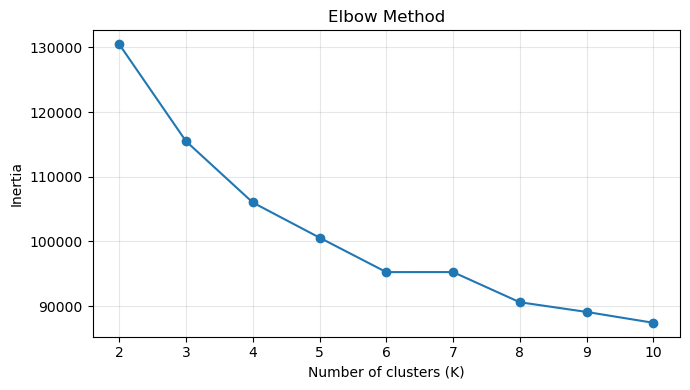

In [112]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, inertias, marker="o")
ax.set(title="Elbow Method", xlabel="Number of clusters (K)", ylabel="Inertia")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Silhouette Score Plot

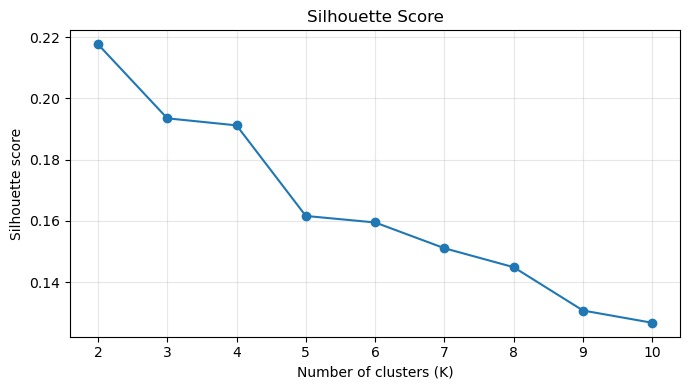

In [113]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, silhouette_scores, marker="o")
ax.set(title="Silhouette Score", xlabel="Number of clusters (K)", ylabel="Silhouette score")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Assign Clusters to Apps

In [114]:
#Fit MiniBatch K-means on the full dataset
kmeans = MiniBatchKMeans(
    n_clusters=chosen_k,
    batch_size=4096,
    n_init=3,
    random_state=42
)
cluster_labels = kmeans.fit_predict(X_cluster)


In [115]:
# Assign each app its fitted cluster label.
clustered_apps = applications_copy.copy()
clustered_apps["Cluster"] = cluster_labels

### Visualizing App Clusters

Each point represents an app from a reproducible sample of up to 25,000 apps; the clustering model itself was fitted on the full dataset. Colors indicate the K-Means cluster assigned to each app, and cluster IDs are arbitrary labels rather than ranks. The x-axis shows installs and the y-axis shows review count. Both axes use `log1p` (log of one plus the value) to make the highly skewed counts easier to compare while retaining zero values. The clusters were learned from the full app-profile feature set, so overlap in this two-feature view is expected.

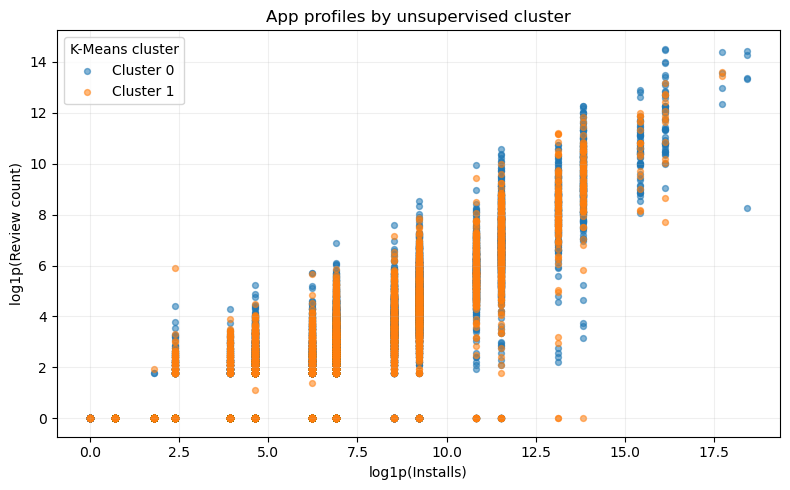

In [116]:
x, y = "Installs", "ReviewCount"

plot_apps = clustered_apps.sample(
    n=min(25_000, len(clustered_apps)), random_state=42
).copy()
plot_apps["Installs_log"] = np.log1p(plot_apps[x].clip(lower=0))
plot_apps["ReviewCount_log"] = np.log1p(plot_apps[y].clip(lower=0))

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap("tab10")

for cluster_id in range(chosen_k):
    mask = plot_apps["Cluster"] == cluster_id
    ax.scatter(
        plot_apps.loc[mask, "Installs_log"],
        plot_apps.loc[mask, "ReviewCount_log"],
        s=18,
        alpha=0.55,
        color=cmap(cluster_id % 10),
        label=f"Cluster {cluster_id}",
    )

ax.set_xlabel("log1p(Installs)")
ax.set_ylabel("log1p(Review count)")
ax.set_title("App profiles by unsupervised cluster")
ax.legend(title="K-Means cluster")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Category Distribution Across App Clusters

In [117]:
# Each row is a category; values show the share of its apps in each cluster.
category_cluster_counts = pd.crosstab(
    clustered_apps["Category"],
    clustered_apps["Cluster"]
)

category_cluster_share = category_cluster_counts.div(
    category_cluster_counts.sum(axis=1),
    axis=0
)

# Rank category pairs by similarity of their cluster distributions.
similarity = cosine_similarity(category_cluster_share.to_numpy())
row_idx, col_idx = np.triu_indices_from(similarity, k=1)

similar_category_pairs = pd.DataFrame({
    "Category_1": category_cluster_share.index.to_numpy()[row_idx],
    "Category_2": category_cluster_share.index.to_numpy()[col_idx],
    "Similarity": similarity[row_idx, col_idx],
}).sort_values("Similarity", ascending=False)

with pd.option_context("display.float_format", "{:.5f}".format):
    display(similar_category_pairs.head(15))

,Category_1,Category_2,Similarity
1005,SOCIAL,WEATHER,1.00000
332,CARD,CASINO,1.00000
808,LIFESTYLE,PERSONALIZATION,1.00000
298,BUSINESS,COMMUNICATION,1.00000
943,PRODUCTIVITY,WORD,1.00000
374,CASINO,ENTERTAINMENT,1.00000
685,FOOD_AND_DRINK,HEALTH_AND_FITNESS,1.00000
338,CARD,ENTERTAINMENT,1.00000
847,MEDICAL,PERSONALIZATION,1.00000
805,LIFESTYLE,MEDICAL,1.00000
